In [1]:
import cv2
import subprocess
import matplotlib.pyplot as plt
from IPython.display import Video, display
import numpy as np
import os

## Read videos

In [ ]:
# Embedded video (works in Jupyter)
video_path = '../data/videos/P1.mp4'
if os.path.exists(video_path):
    display(Video(video_path, embed=True, width=640))
else:
    print('Video not found:', video_path)

# If you want to stream frames (outside notebook), use cv2.VideoCapture as in scripts.

In [2]:
# Get fps and basic info
video_path = '../data/videos/P1.mp4'
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
cap.release()

FPS=35.99074097120243, frames=22413, duration(s)=622.74


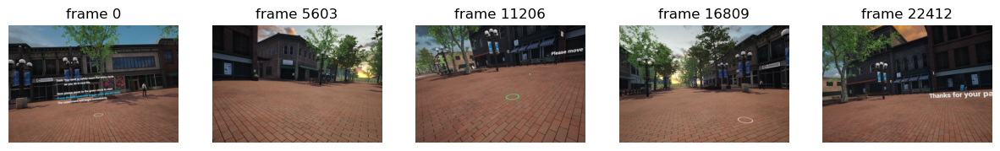

In [10]:
# Sample and show/save frames evenly across the video
def sample_frames(path, n_samples=5, out_dir=None):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        print('Cannot open', path)
        return []
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total == 0:
        cap.release()
        print('Video has 0 frames')
        return []
    # idxs = np.linspace(0, max(0, total-1), n_samples, dtype=int)
    idxs = np.arange(n_samples)
    frames = []
    if out_dir:
        os.makedirs(out_dir, exist_ok=True)
    for i in idxs:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
        ret, frame = cap.read()
        if not ret:
            continue
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frames.append((int(i), rgb))
        if out_dir:
            fname = os.path.join(out_dir, f'frame_{i:06d}.jpg')
            cv2.imwrite(fname, frame)
    cap.release()
    return frames

# show sampled frames
sampled_5 = sample_frames('../data/videos/P1.mp4', n_samples=5, out_dir='../data/frames/P1')
if sampled:
    fig, axs = plt.subplots(1, len(sampled), figsize=(15, 5))
    for ax, (i, fr) in zip(axs, sampled):
        ax.imshow(fr)
        ax.set_title(f'frame {i}')
        ax.axis('off')
    plt.show()
else:
    print('No frames sampled')

In [9]:
sampled[0][1].shape

(1068, 1536, 3)

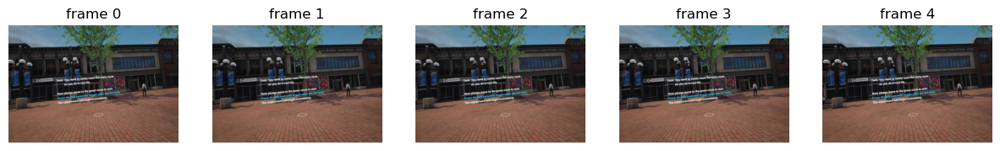

In [12]:
if sampled_5:
    fig, axs = plt.subplots(1, len(sampled_5), figsize=(15, 5))
    for ax, (i, fr) in zip(axs, sampled_5):
        ax.imshow(fr)
        ax.set_title(f'frame {i}')
        ax.axis('off')
    plt.show()
else:
    print('No frames sampled')

## Clip videos

In [37]:
# Get fps and basic info
video_path = '../data/rawvideos/P1.mp4'
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

FPS=35.99074097120243, frames=22413, duration(s)=622.74


In [38]:
5*60*36

10800

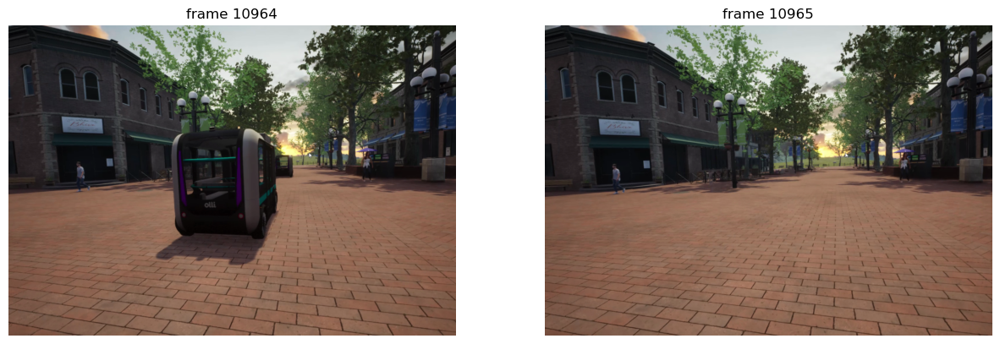

In [39]:
frames = []
for i in [10964, 10965]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))


fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [5]:
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)
start_frame = 10764
end_frame = 10964
start_frame, end_frame

(10764, 10964)

In [47]:
# --- Prepare output writer ---
output_path = "clipped.mp4"
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

# --- Skip frames before start ---
cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame)

# --- Write frames in range ---
for i in range(start_frame, end_frame):
    ret, frame = cap.read()
    if not ret:
        break
    out.write(frame)

# --- Cleanup ---
cap.release()
out.release()
print(f"Saved clipped video to {output_path}")

Saved clipped video to clipped.mp4


In [8]:
start_frame/fps, end_frame/fps

(299.07692116182574, 304.63390594744124)

In [21]:
299.068733 + 5.441395

304.510128

In [32]:
299.096533 + 5.441395

304.537928

In [68]:
# command = [
#     "ffmpeg",
#     "-ss", str(start_frame/fps),
#     "-to", str(end_frame/fps),
#     "-i", '../data/rawvideos/P1.mp4',
#     "-c", "copy",
#     "-avoid_negative_ts", "1",
#     output_path
# ]

# start_time = 299.124300
# end_time = 304.626967
# output_path = "../data/videoclips/P1S1.mp4"

# start_time = 299.124300 + start_s2 - start
# end_time = 299.124300 + (end_s2 - start)
# output_path = "../data/videoclips/P1S2.mp4"

start_time = 299.124300 + start_s3 - start
end_time = 299.124300 + (end_s3 - start)
output_path = "../data/videoclips/P1S3.mp4"

command = [
    "ffmpeg",
    "-i", '../data/rawvideos/P1.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 335.3590289999999–342.90970599999997 saved to ../data/videoclips/P1S3.mp4


In [66]:
1/30

0.03333333333333333

In [50]:
304.626967 - 299.124300

5.502666999999974

In [67]:
start = 313.513266
end_s1 = 318.954661
start_s2 = 332.194421
end_s2 = 337.446538
start_s3 = 349.717995 + 0.03
end_s3 = 357.268672 + 0.03

In [52]:
start_s2 - start

18.68115499999999

In [27]:
10764 / 35.99074097120243

299.07692116182574

In [34]:
5.44*36

195.84

In [28]:
318.954661 - 313.513266

5.441395

In [59]:
# Get fps and basic info
video_path = '../data/videoclips/P1S2.mp4'
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

FPS=29.97002997002997, frames=158, duration(s)=5.27


In [61]:
end_s2 - start_s2

5.252116999999998

In [58]:
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
width, height 

(1536, 1068)

In [49]:
# Get fps and basic info
video_path = '../data/videoclips/P1S1_6.mp4'
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

## TODO: problem is because the -ss and -to are not accurate enough... 

FPS=29.97002997002997, frames=168, duration(s)=5.61


In [23]:
def get_frame_time(video_path, frame_index):
    container = av.open(video_path)
    stream = container.streams.video[0]
    
    # Decode frames one by one until we reach the desired index
    for i, frame in enumerate(container.decode(stream)):
        if i == frame_index:
            timestamp = float(frame.pts * stream.time_base)
            container.close()
            return timestamp
    container.close()
    raise IndexError("Frame index out of range")

def get_frame_time_fast(video_path, frame_index):
    container = av.open(video_path)
    stream = container.streams.video[0]
    
    # Roughly estimate where to seek (using average frame rate)
    avg_fps = float(stream.average_rate)
    approx_time = frame_index / avg_fps
    container.seek(int(approx_time / stream.time_base), any_frame=True, backward=True)
    
    # Decode from that point
    for i, frame in enumerate(container.decode(stream)):
        if frame.index == frame_index:
            return float(frame.pts * stream.time_base)
    container.close()
    raise IndexError("Frame not found")

In [31]:
# Example
video_path = "../data/rawvideos/P1.mp4"
frame_index = 10764 + 1
t = get_frame_time(video_path, frame_index)
print(f"Frame {frame_index} occurs at {t:.6f} seconds")

Frame 10765 occurs at 299.096533 seconds


In [26]:
# Example
video_path = "../data/videoclips/P1.mp4"
frame_index = 10964 + 1
t = get_frame_time(video_path, frame_index)
print(f"Frame {frame_index} occurs at {t:.6f} seconds")

NameError: name 'get_frame_time' is not defined

In [17]:
304.654767 - 299.096533

5.55823399999997

In [35]:
78-42

36

## Get the first frame timepoint

### P1

In [2]:
# Get fps and basic info
filename = 'P1'
pid = 1

video_path = f'../data/rawvideos/videos/{filename}.mp4'
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

FPS=35.99074097120243, frames=22413, duration(s)=622.74


FOR PERSON 1 in VIDEO= ../data/rawvideos/P1.mp4


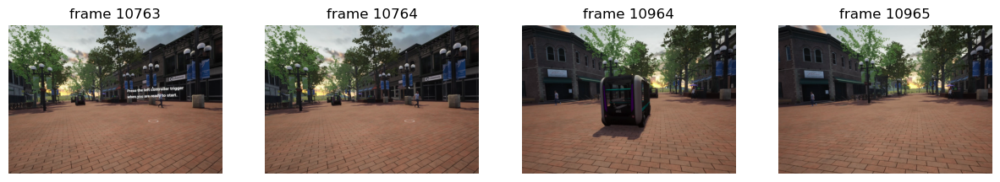

In [6]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [10763, 10764, 10964, 10965]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [8]:
# check visually 
start = 299.124300
start_s1 = 313.513266
end_s1 = 318.954661

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 299.1243–304.565695 saved to ../data/videoclips/testP1S1.mp4


### P13

In [11]:
(3*60+47)*36

8172

In [10]:
# Get fps and basic info
filename = 'P13'
pid = 13

video_path = f'../data/rawvideos/videos/{filename}.mp4'
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

FPS=35.993389607246236, frames=17731, duration(s)=492.62


FOR PERSON 13 in VIDEO= ../data/rawvideos/videos/P13.mp4


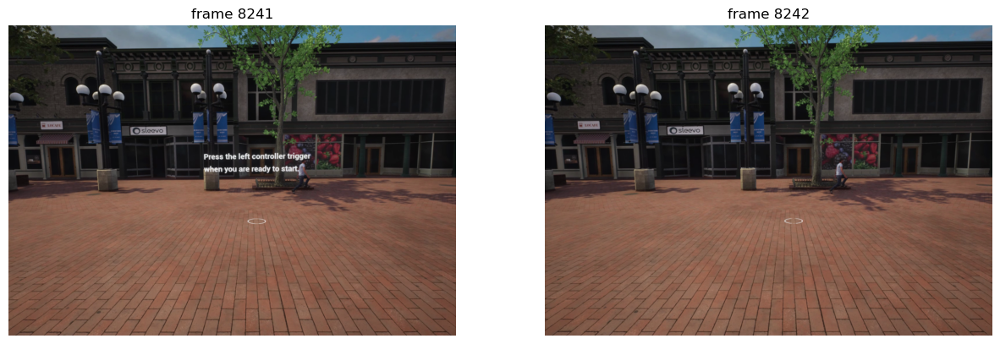

In [17]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [8241, 8242]: # 8241, 8242
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [23]:
# check visually 
start = 229.027867
start_s1 = 236.193049
end_s1 = 242.687872

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), 
    "-to", str(end_time), 
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 229.000067–235.49489 saved to ../data/videoclips/testP13S.mp4


### P22

In [24]:
(3*60+16)*36

7056

In [26]:
# Get fps and basic info
filename = 'P22'
pid = 22

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P22.mp4
FPS=35.9945119950598, frames=16006, duration(s)=444.68


FOR PERSON 22 in VIDEO= ../data/rawvideos/videos/P22.mp4


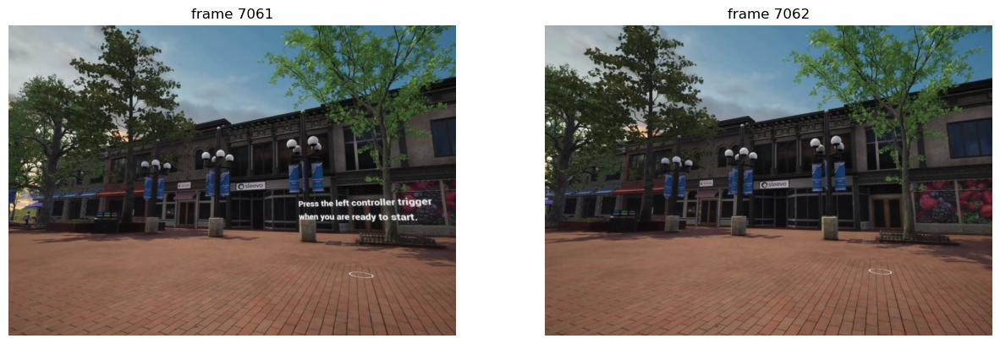

In [32]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [7061, 7062]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [35]:
# check visually 
start = 196.238100
start_s1 = 208.382221
end_s1 = 218.631286

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 196.210267–206.459332 saved to ../data/videoclips/testP22S.mp4


### P2

In [37]:
(3*60+22)*36

7272

In [36]:
# Get fps and basic info
filename = 'P2'
pid = 2

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P2.mp4
FPS=35.99317851950238, frames=17178, duration(s)=477.26


FOR PERSON 2 in VIDEO= ../data/rawvideos/videos/P2.mp4


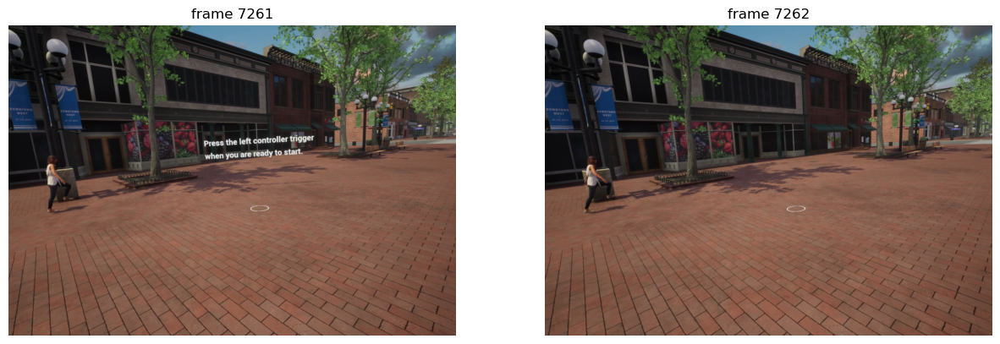

In [43]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [7261, 7262]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [45]:
# check visually 
start = 201.790367
start_s1 = 345.372988
end_s1 = 353.474428

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 201.762567–209.86400699999996 saved to ../data/videoclips/testP2S.mp4


### P3

In [ ]:
(3*60+22)*36

7272

In [46]:
# Get fps and basic info
filename = 'P3'
pid = 3

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P3.mp4
FPS=36.00975552751911, frames=6656, duration(s)=184.84


FOR PERSON 3 in VIDEO= ../data/rawvideos/videos/P3.mp4


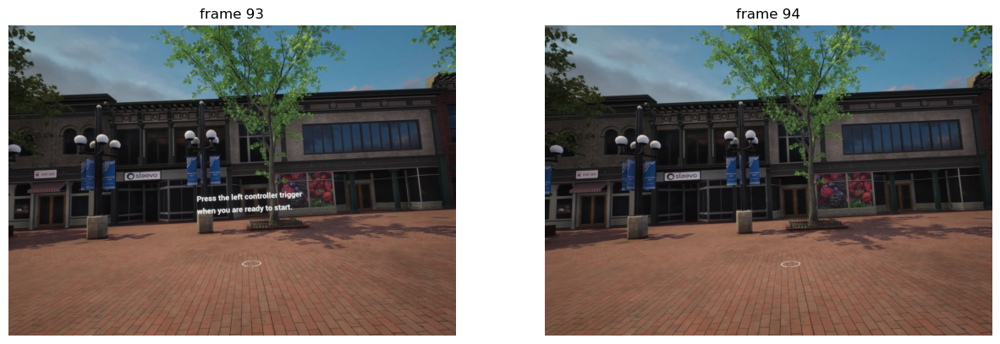

In [50]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [93, 94]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [52]:
# check visually 
start = 2.646100
start_s1 = 467.247036
end_s1 = 474.989137

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 2.6461–10.388201000000048 saved to ../data/videoclips/testP3S.mp4


### P6

In [54]:
(3*60+18)*36

7128

In [53]:
# Get fps and basic info
filename = 'P6'
pid = 6

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P6.mp4
FPS=35.99386810856631, frames=16781, duration(s)=466.22


FOR PERSON 6 in VIDEO= ../data/rawvideos/videos/P6.mp4


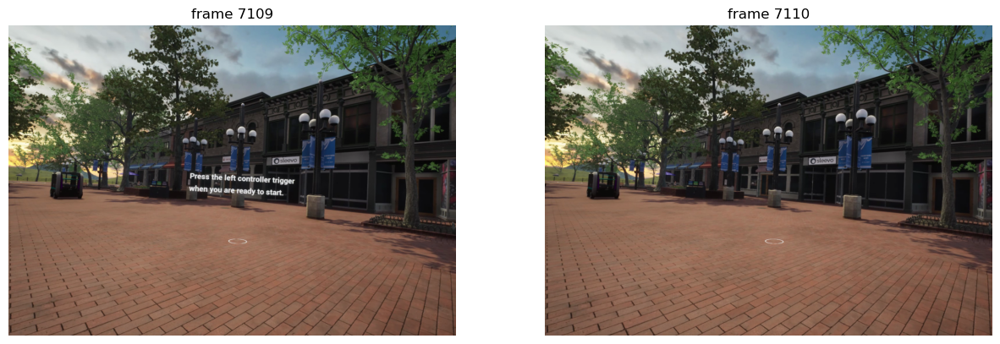

In [61]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [7109, 7110]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [62]:
# check visually 
start = 197.575067
start_s1 = 416.686344
end_s1 = 429.183673

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 197.575067–210.07239599999997 saved to ../data/videoclips/testP6S.mp4


### P7

In [64]:
(5*60+44)*36

12384

In [63]:
# Get fps and basic info
filename = 'P7'
pid = 7

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P7.mp4
FPS=35.990687690270384, frames=22277, duration(s)=618.97


FOR PERSON 7 in VIDEO= ../data/rawvideos/videos/P7.mp4


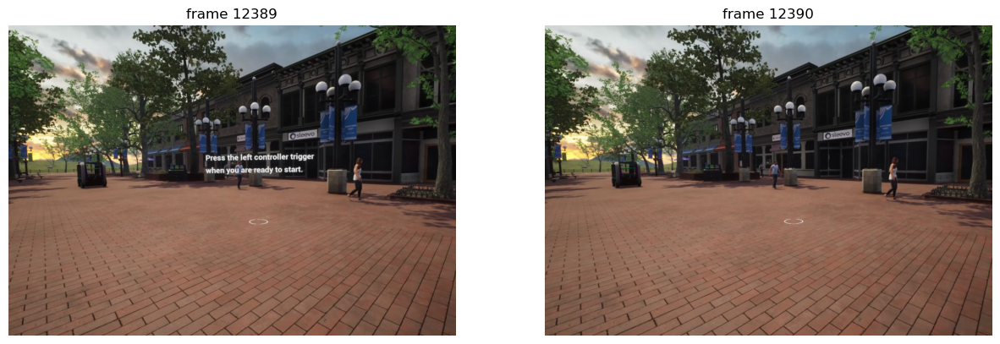

In [66]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [12389, 12390]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [67]:
# check visually 
start = 344.320567
start_s1 = 515.702678
end_s1 = 526.286847

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 344.320567–354.90473599999996 saved to ../data/videoclips/testP7S.mp4


## P8

In [68]:
(4*60+9)*36

8964

In [69]:
# Get fps and basic info
filename = 'P8'
pid = 8

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P8.mp4
FPS=35.99190483195395, frames=20324, duration(s)=564.68


FOR PERSON 8 in VIDEO= ../data/rawvideos/videos/P8.mp4


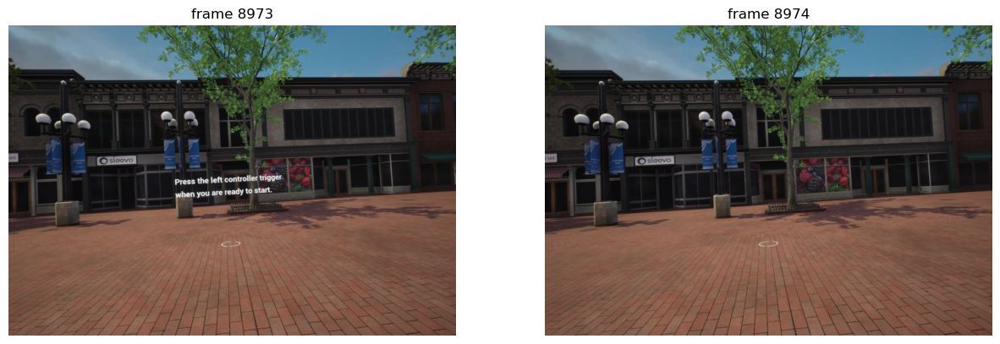

In [75]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [8973, 8974]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [76]:
# check visually 
start = 249.372233
start_s1 = 545.357234
end_s1 = 559.349752

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 249.372233–263.364751 saved to ../data/videoclips/testP8S.mp4


## P19

In [78]:
(5*60+35)*36

12060

In [77]:
# Get fps and basic info
filename = 'P19'
pid = 19

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P19.mp4
FPS=35.99052506440644, frames=20638, duration(s)=573.43


FOR PERSON 19 in VIDEO= ../data/rawvideos/videos/P19.mp4


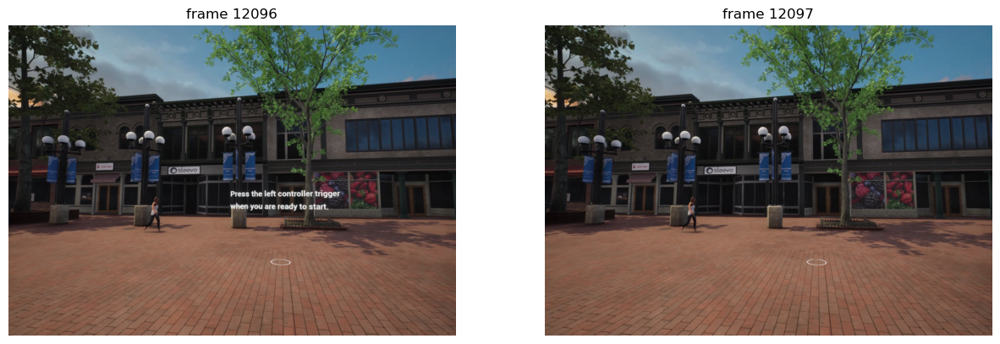

In [85]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [12096, 12097]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [86]:
# check visually 
start = 336.181600
start_s1 = 449.085298
end_s1 = 464.431212

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 336.1816–351.527514 saved to ../data/videoclips/testP19S.mp4


## P28

In [88]:
(6*60+31)*36

14076

In [102]:
# Get fps and basic info
filename = 'P28'
pid = 28

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P28.mp4
FPS=35.99021631321928, frames=25063, duration(s)=696.38


FOR PERSON 28 in VIDEO= ../data/rawvideos/videos/P28.mp4


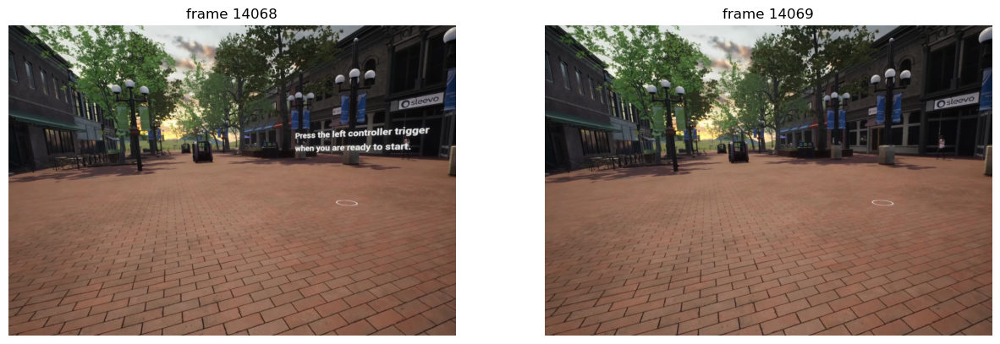

In [103]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [14068, 14069]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [104]:
# check visually 
start = 390.974267
start_s1 = 524.046241
end_s1 = 535.340384

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 390.974267–402.26840999999996 saved to ../data/videoclips/testP28S.mp4


## P32

In [97]:
(4*60+21)*36

9396

In [96]:
# Get fps and basic info
filename = 'P32'
pid = 32

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P32.mp4
FPS=35.99325461388319, frames=17867, duration(s)=496.40


FOR PERSON 32 in VIDEO= ../data/rawvideos/videos/P32.mp4


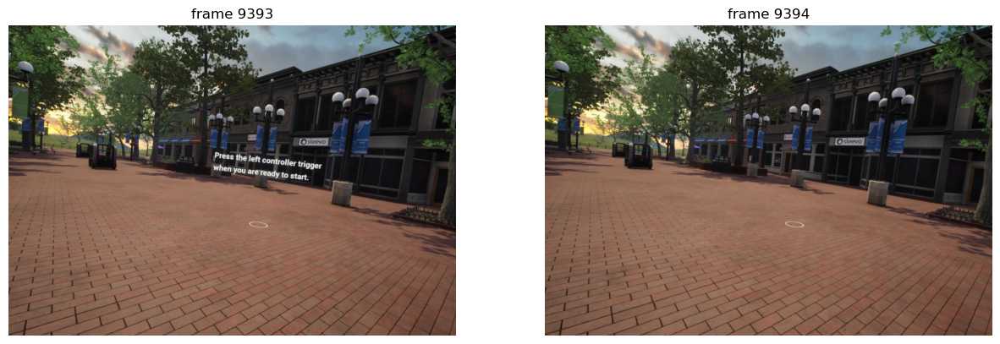

In [100]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [9393, 9394]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [101]:
# check visually 
start = 261.045433
start_s1 = 404.490926
end_s1 = 414.688012

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 261.045433–271.242519 saved to ../data/videoclips/testP32S.mp4


## P35

In [106]:
(5*60+50)*36

12600

In [105]:
# Get fps and basic info
filename = 'P35'
pid = 35

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P35.mp4
FPS=35.99179305153134, frames=20726, duration(s)=575.85


FOR PERSON 35 in VIDEO= ../data/rawvideos/videos/P35.mp4


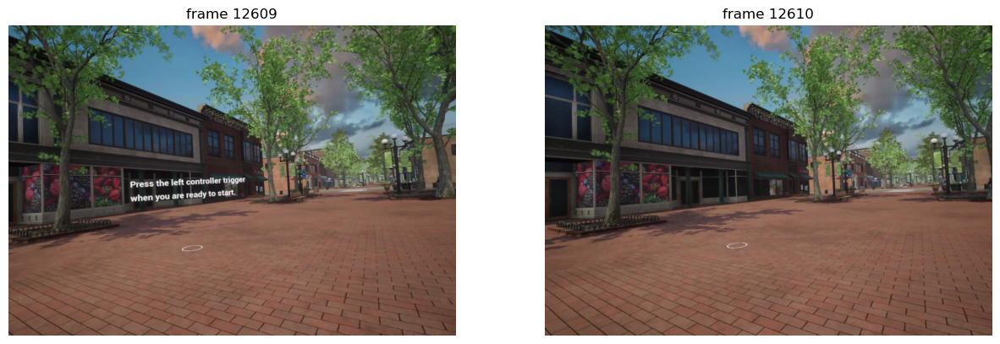

In [111]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [12609, 12610]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [112]:
# check visually 
start = 350.417700
start_s1 = 557.936503
end_s1 = 564.33063

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 350.4177–356.81182700000005 saved to ../data/videoclips/testP35S.mp4


## P42

In [122]:
(5*60+15)*36

11340

In [123]:
# Get fps and basic info
filename = 'P42'
pid = 42

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P42.mp4
FPS=35.99160747651713, frames=19132, duration(s)=531.57


FOR PERSON 42 in VIDEO= ../data/rawvideos/videos/P42.mp4


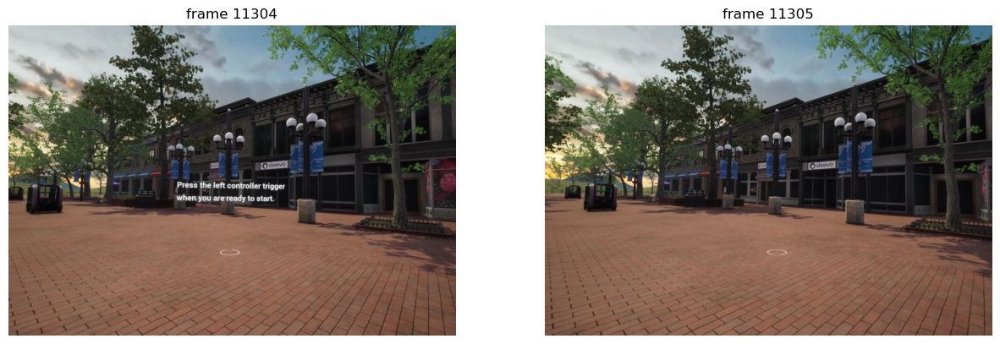

In [128]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [11304, 11305]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [132]:
# check visually 
start = 295.963100
start_s1 = 455.189242
end_s1 = 462.027459
# start = 314.194067
# start_s1 = 473.44166
# end_s1 = 483.881104

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 295.9631–302.80131700000004 saved to ../data/videoclips/testP42S.mp4


In [130]:
473.44166 - 455.189242

18.252418000000034

In [131]:
314.194067 - 18.252418000000034

295.941649

## P43

In [134]:
(4*60+34)*36

9864

In [133]:
# Get fps and basic info
filename = 'P43'
pid = 43

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P43.mp4
FPS=35.99349467419958, frames=17442, duration(s)=484.59


FOR PERSON 43 in VIDEO= ../data/rawvideos/videos/P43.mp4


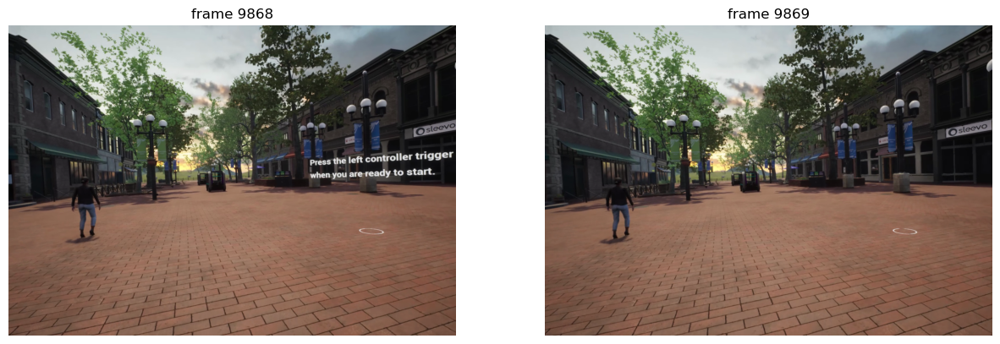

In [138]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [9868, 9869]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [142]:
# check visually 
start = 238.788700
start_s1 = 408.398212
end_s1 = 433.2865
# start = 274.278000
# start_s1 = 443.892602
# end_s1 = 459.777457

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 238.7887–263.676988 saved to ../data/videoclips/testP43S.mp4


In [141]:
274.278000 - (443.892602 - 408.398212)

238.78361

## P45

In [144]:
(6*60+1)*36

12996

In [143]:
# Get fps and basic info
filename = 'P45'
pid = 45

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P45.mp4
FPS=35.991437657982004, frames=21594, duration(s)=599.98


FOR PERSON 45 in VIDEO= ../data/rawvideos/videos/P45.mp4


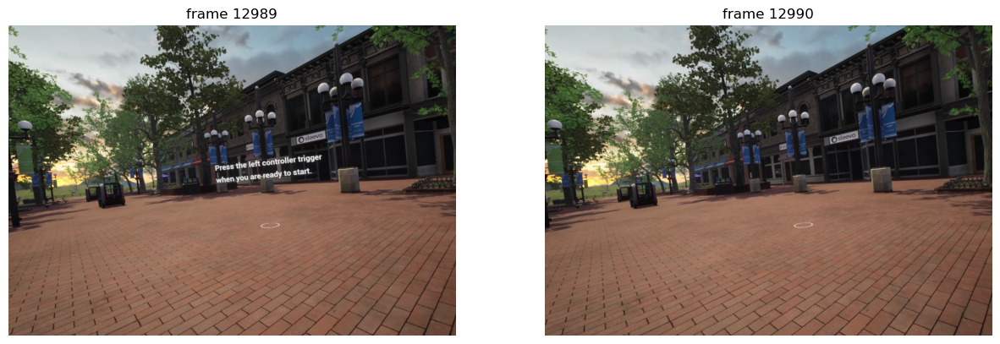

In [150]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [12989, 12990]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [151]:
# check visually 
start = 361.009833
start_s1 = 516.951644
end_s1 = 526.94887
# start = 274.278000
# start_s1 = 443.892602
# end_s1 = 459.777457

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 361.009833–371.0070590000001 saved to ../data/videoclips/testP45S.mp4


## P4

In [152]:
(5*60+31)*36

11916

In [153]:
# Get fps and basic info
filename = 'P4-1'
pid = 4

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P4-1.mp4
FPS=35.991080639671495, frames=22308, duration(s)=619.82


FOR PERSON 4 in VIDEO= ../data/rawvideos/videos/P4-1.mp4


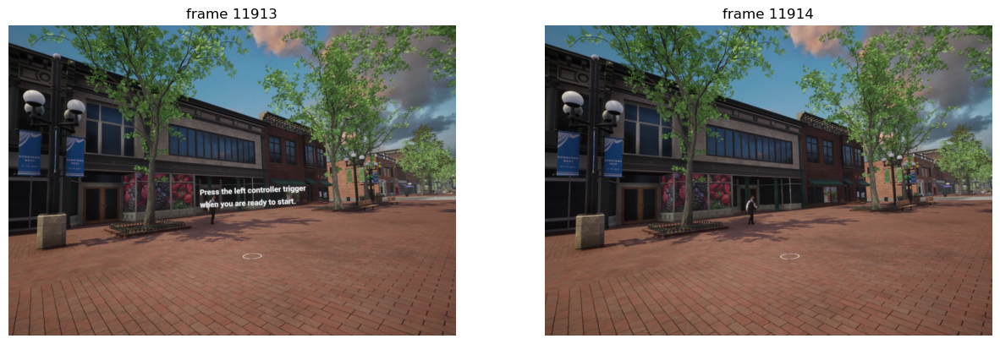

In [158]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [11913, 11914]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [159]:
# check visually 
start = 331.084133
start_s1 = 537.276603
end_s1 = 550.911037
# start = 274.278000
# start_s1 = 443.892602
# end_s1 = 459.777457

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 331.084133–344.71856699999995 saved to ../data/videoclips/testP4S.mp4


In [161]:
(0*60+9)*36

324

In [160]:
# Get fps and basic info
filename = 'P4-2'
pid = 4

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P4-2.mp4
FPS=36.151598492985904, frames=1123, duration(s)=31.06


FOR PERSON 4 in VIDEO= ../data/rawvideos/videos/P4-2.mp4


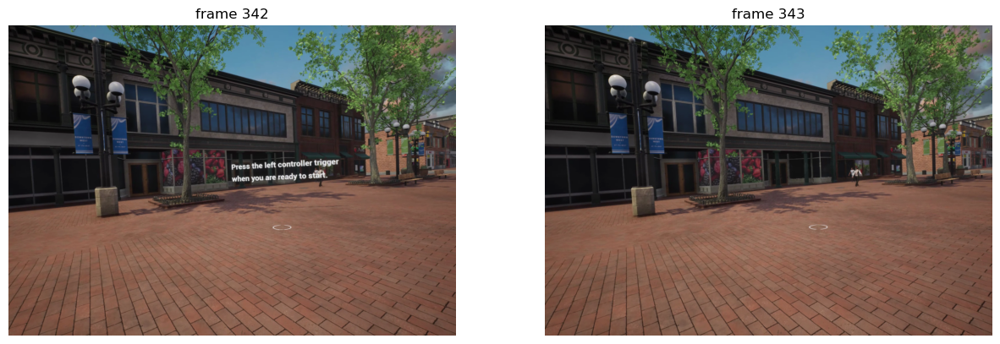

In [166]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [342, 343]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [168]:
# check visually 
start = 9.538800
start_s1 = 18.673017
end_s1 = 35.681634

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 9.5388–26.547417000000003 saved to ../data/videoclips/testP4S.mp4


## P5

In [171]:
(3*60+47)*36

8172

In [170]:
# Get fps and basic info
filename = 'P5-2'
pid = 5

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P5-2.mp4
FPS=35.99824384290827, frames=12094, duration(s)=335.96


FOR PERSON 5 in VIDEO= ../data/rawvideos/videos/P5-2.mp4


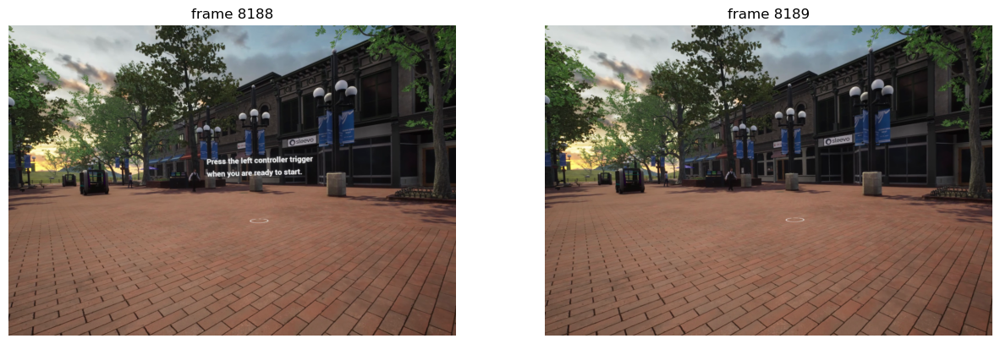

In [176]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [8188, 8189]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [177]:
# check visually 
start = 227.554433
start_s1 = 365.793515
end_s1 = 377.742659

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 227.554433–239.50357699999998 saved to ../data/videoclips/testP5S.mp4


In [179]:
(0*60+35)*36

1260

In [180]:
# Get fps and basic info
filename = 'P5-3'
pid = 5

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P5-3.mp4
FPS=36.03163388847218, frames=3859, duration(s)=107.10


FOR PERSON 5 in VIDEO= ../data/rawvideos/videos/P5-3.mp4


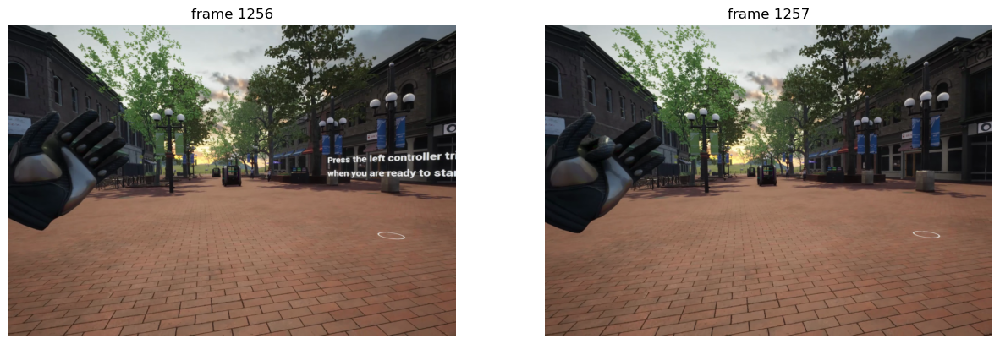

In [184]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [1256, 1257]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [186]:
# check visually 
start = 34.941600
start_s1 = 56.181407
end_s1 = 65.477146

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 34.9416–44.237339000000006 saved to ../data/videoclips/testP5S.mp4


In [187]:
34.941600 - (56.181407 - 38.755185)

17.515378

## P9

In [188]:
(1*60+46)*36

3816

In [189]:
# Get fps and basic info
filename = 'P9-1'
pid = 9

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P9-1.mp4
FPS=36.00026614590486, frames=10713, duration(s)=297.58


FOR PERSON 9 in VIDEO= ../data/rawvideos/videos/P9-1.mp4


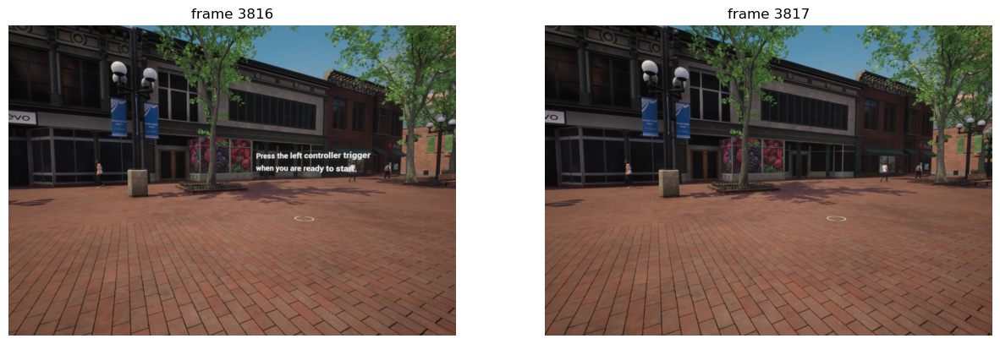

In [193]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [3816, 3817]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [194]:
# check visually 
start = 106.079033
start_s1 = 180.389208
end_s1 = 186.584127

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 106.079033–112.273952 saved to ../data/videoclips/testP9S.mp4


## P10

In [195]:
(0*60+36)*36

1296

In [196]:
# Get fps and basic info
filename = 'P10-2'
pid = 10

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P10-2.mp4
FPS=36.00044393886063, frames=10088, duration(s)=280.22


FOR PERSON 10 in VIDEO= ../data/rawvideos/videos/P10-2.mp4


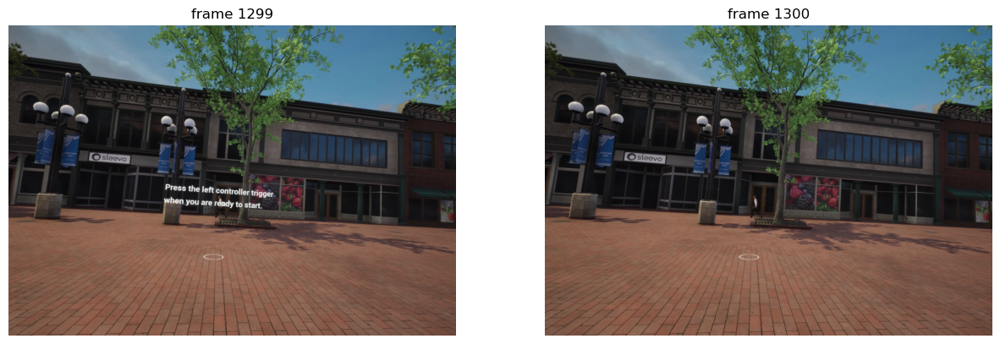

In [199]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [1299, 1300]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [201]:
# check visually 
start = 36.156933
start_s1 = 42.502172
end_s1 = 49.447437

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 36.156933–43.102198 saved to ../data/videoclips/testP10S.mp4


## P11

In [202]:
(4*60+22)*36

9432

In [203]:
# Get fps and basic info
filename = 'P11-2'
pid = 11

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P11-2.mp4
FPS=35.992997693846576, frames=18373, duration(s)=510.46


FOR PERSON 11 in VIDEO= ../data/rawvideos/videos/P11-2.mp4


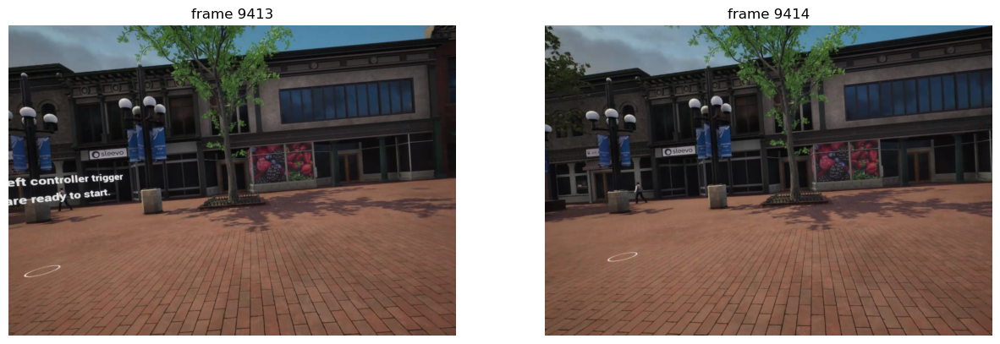

In [217]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [9413, 9414]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [218]:
# check visually 
start = 261.629567
start_s1 = 301.780297
end_s1 = 311.769193

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 261.629567–271.61846299999996 saved to ../data/videoclips/testP11S.mp4


In [220]:
(0*60+14)*36

504

In [221]:
# Get fps and basic info
filename = 'P11-3'
pid = 11

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P11-3.mp4
FPS=36.141481044624896, frames=1195, duration(s)=33.06


FOR PERSON 11 in VIDEO= ../data/rawvideos/videos/P11-3.mp4


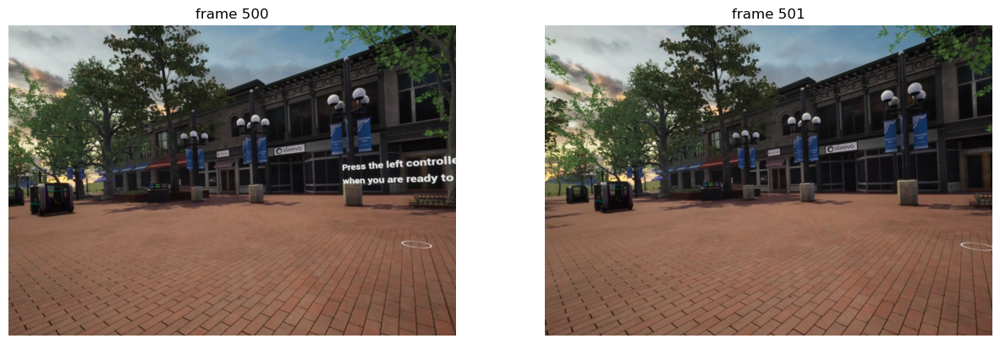

In [232]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [500, 501]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [233]:
# check visually 
start = 13.929200
start_s1 = 22.669471
end_s1 = 37.819136

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 13.9292–29.078865 saved to ../data/videoclips/testP11S.mp4


## P12

In [242]:
(7*60+8)*36

15408

In [235]:
# Get fps and basic info
filename = 'P12-1'
pid = 12

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P12-1.mp4
FPS=35.99031780317763, frames=24792, duration(s)=688.85


FOR PERSON 12 in VIDEO= ../data/rawvideos/videos/P12-1.mp4


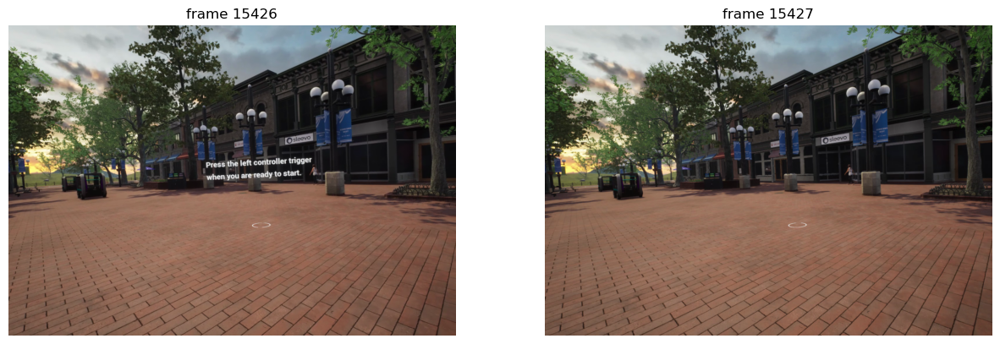

In [247]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [15426, 15427]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [248]:
# check visually 
start = 428.708967
start_s1 = 520.070449
end_s1 = 531.676689

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 428.708967–440.31520699999993 saved to ../data/videoclips/testP12S.mp4


In [250]:
(0*60+46)*36

1656

In [249]:
# Get fps and basic info
filename = 'P12-2'
pid = 12

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P12-2.mp4
FPS=36.06045123694012, frames=2435, duration(s)=67.53


FOR PERSON 12 in VIDEO= ../data/rawvideos/videos/P12-2.mp4


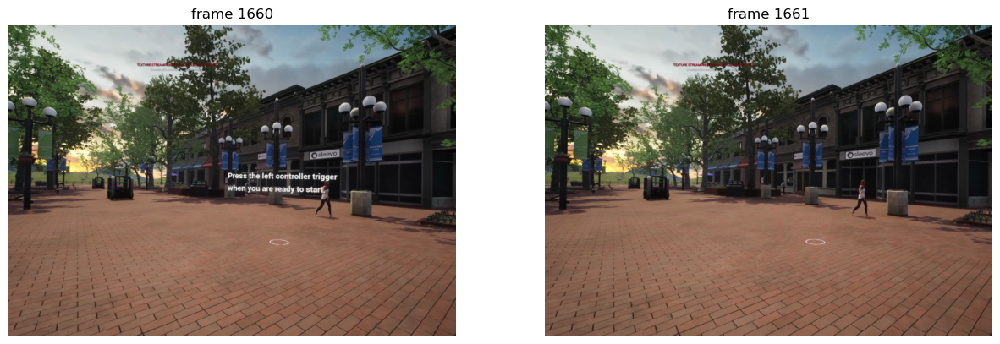

In [257]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [1660, 1661]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [259]:
# check visually 
start = 46.168967
start_s1 = 39.358893
end_s1 = 63.505889

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 46.168967–70.31596300000001 saved to ../data/videoclips/testP12S.mp4


In [261]:
(0*60+11)*36

396

In [260]:
# Get fps and basic info
filename = 'P12-3'
pid = 12

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P12-3.mp4
FPS=36.09457033114389, frames=1694, duration(s)=46.93


FOR PERSON 12 in VIDEO= ../data/rawvideos/videos/P12-3.mp4


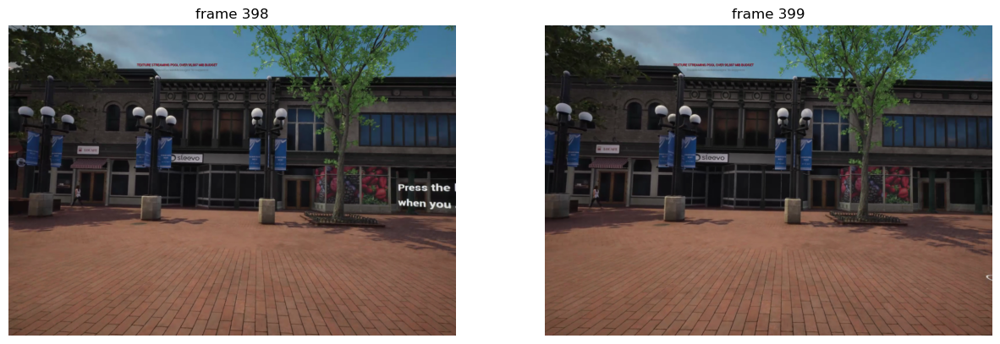

In [265]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [398, 399]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [266]:
# check visually 
start = 11.092767
start_s1 = 16.199554
end_s1 = 26.863804

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 11.092767–21.757016999999998 saved to ../data/videoclips/testP12S.mp4


## Check eye gaze overlay

In [276]:
# Get fps and basic info

video_path = f'../data/videoclips/P1/P1S1.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    width  = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}, width={width}, height={height}')
# cap.release()

VIDEO= ../data/videoclips/P1/P1S1.mp4
FPS=29.97002997002997, frames=164, duration(s)=5.47, width=1536, height=1068


FOR PERSON 1 in VIDEO= ../data/videoclips/P1/P1S1.mp4
Read frame 6, shape=(1068, 1536, 3)
Read frame 7, shape=(1068, 1536, 3)


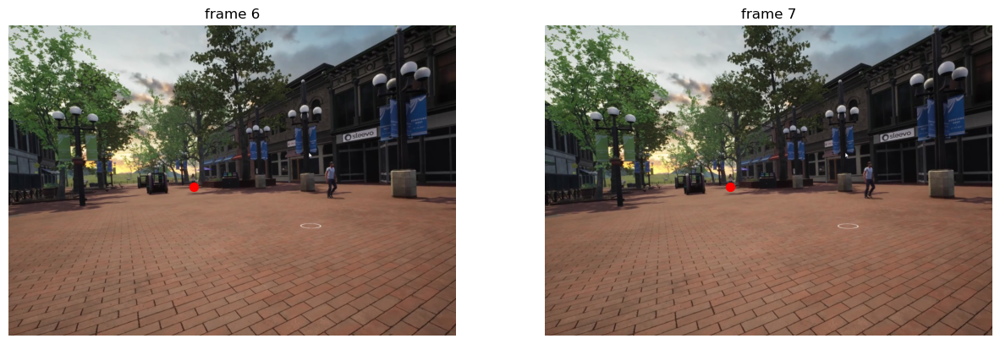

In [300]:
video_path = f'../data/videoclips/P1/P1S1.mp4'
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [6, 7]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))
    print(f"Read frame {i}, shape={frame.shape}")

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.scatter([1536 - 900.0551605072492], [1068 - 511.6608936482349], c='red', s=50)
    ax.axis('off')
plt.show()

In [279]:
(314.068482 - 313.513266)/0.03

18.507200000001

FOR PERSON 1 in VIDEO= ../data/videoclips/P1/P1S1.mp4
Read frame 17, shape=(1068, 1536, 3)
Read frame 18, shape=(1068, 1536, 3)
Read frame 19, shape=(1068, 1536, 3)
Read frame 20, shape=(1068, 1536, 3)


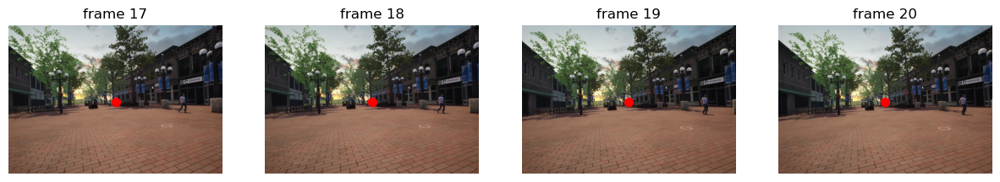

In [306]:
video_path = f'../data/videoclips/P1/P1S1.mp4'
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [17, 18, 19, 20]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))
    print(f"Read frame {i}, shape={frame.shape}")

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}') 
    ax.scatter([1536 - 766.5507995103078], [1068 - 515.1682437267552], c='red', s=50) # 左右是对的，上下是颠倒的
    ax.axis('off')
plt.show()

In [301]:
(316.650175 - 313.513266)/0.03

104.56363333333343

FOR PERSON 1 in VIDEO= ../data/videoclips/P1/P1S1.mp4
Read frame 101, shape=(1068, 1536, 3)
Read frame 102, shape=(1068, 1536, 3)
Read frame 103, shape=(1068, 1536, 3)
Read frame 104, shape=(1068, 1536, 3)
Read frame 105, shape=(1068, 1536, 3)
Read frame 106, shape=(1068, 1536, 3)
Read frame 107, shape=(1068, 1536, 3)


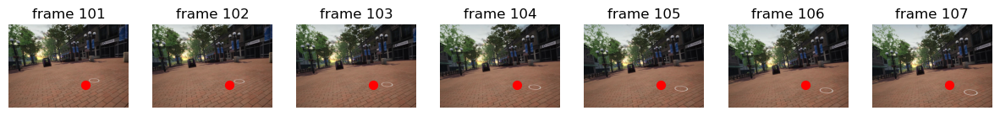

In [305]:
video_path = f'../data/videoclips/P1/P1S1.mp4'
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [101, 102, 103, 104, 105, 106, 107]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))
    print(f"Read frame {i}, shape={frame.shape}")

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}') 
    ax.scatter([1536 - 551.5353156638216], [1068 - 297.05048877614206], c='red', s=50) # 左右是对的，上下是颠倒的
    ax.axis('off')
plt.show()